In [1]:
library(data.table)
library(ggplot2)
library(ggrepel)

Warning message:
“程辑包‘ggplot2’是用R版本4.1.3 来建造的”


# PBMC

In [2]:
ct = 'CD4T'
DEG <- readRDS(paste0(ct,'_disease_DEG_new.rds'))
meta = read.csv(paste0(ct,'_eqtl_meta_results_GWASrisk.csv'))

In [3]:
re = intersect(meta$Gene,rownames(DEG))

logFC_cutoff <- 0.5
pval_cutoff <- 0.05
DEG$negLogP <- -log10(DEG$p_val_adj)

df = DEG[re,]
# 添加显著性分组
df$regulation <- "Not Sig"
df$regulation[df$avg_log2FC > logFC_cutoff & df$p_val_adj < pval_cutoff] <- "Up"
df$regulation[df$avg_log2FC < -logFC_cutoff & df$p_val_adj < pval_cutoff] <- "Down"

max_finite <- max(df$negLogP[is.finite(df$negLogP)], na.rm = TRUE)

df$negLogP[is.infinite(df$negLogP)] <- max_finite

upGenes <- df[df$regulation == 'Up',]
upGenes= upGenes[order(upGenes$p_val_adj),][1:6,]
upGenes$gene = rownames(upGenes)

In [4]:
dim(df[df$regulation == 'Up',])

[1] 39  7

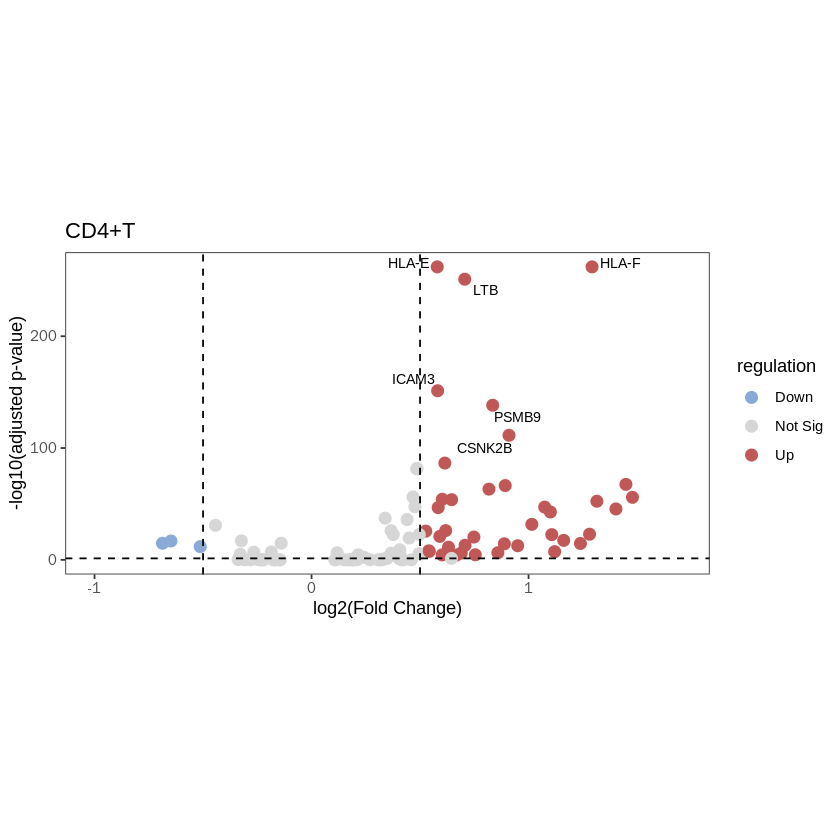

In [5]:
p1 <- ggplot(df, aes(x = avg_log2FC, y = negLogP, color = regulation)) +
  geom_point(alpha = 1, size = 3) +
  scale_color_manual(values = c("Down"="#8AA9D6", "Not Sig" = "#D6D6D6", "Up" = "#C15858")) +
  geom_vline(xintercept = c(-logFC_cutoff, logFC_cutoff), 
             linetype = "dashed", color = "black") +
  geom_hline(yintercept = -log10(pval_cutoff), 
             linetype = "dashed", color = "black") +
  theme_bw() +
  labs(x = "log2(Fold Change)", y = "-log10(adjusted p-value)", 
       title = "CD4+T")+theme(aspect.ratio = 1,panel.grid = element_blank(),
  )+xlim(-1,1.7)+geom_text_repel(
    data = upGenes,
    aes(label = gene),
    size = 3,
    color = "black",
    max.overlaps = 21  
  )+theme(aspect.ratio = 0.5)
p1

In [6]:
ct = 'CD8T'
DEG <- readRDS(paste0(ct,'_disease_DEG_new.rds'))
meta = read.csv(paste0(ct,'_eqtl_meta_results_GWASrisk.csv'))

re = intersect(meta$Gene,rownames(DEG))

logFC_cutoff <- 0.5
pval_cutoff <- 0.05
DEG$negLogP <- -log10(DEG$p_val_adj)

df = DEG[re,]
# 添加显著性分组
df$regulation <- "Not Sig"
df$regulation[df$avg_log2FC > logFC_cutoff & df$p_val_adj < pval_cutoff] <- "Up"
df$regulation[df$avg_log2FC < -logFC_cutoff & df$p_val_adj < pval_cutoff] <- "Down"

max_finite <- max(df$negLogP[is.finite(df$negLogP)], na.rm = TRUE)

df$negLogP[is.infinite(df$negLogP)] <- max_finite

upGenes <- df[df$regulation == 'Up',]
upGenes= upGenes[order(upGenes$p_val_adj),][1:6,]
upGenes$gene = rownames(upGenes)

dim(df[df$regulation == 'Up',])

[1] 37  7

Warning message:
“Removed 1 rows containing missing values (`geom_point()`).”


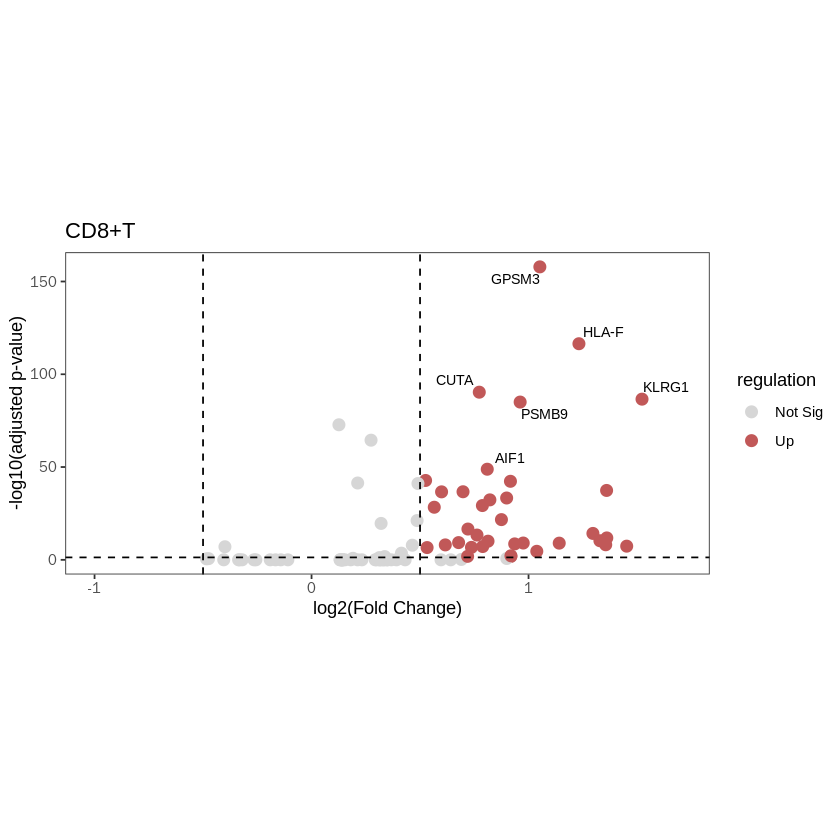

In [7]:
p2 <- ggplot(df, aes(x = avg_log2FC, y = negLogP, color = regulation)) +
  geom_point(alpha = 1, size = 3) +
  scale_color_manual(values = c("Down"="#8AA9D6", "Not Sig" = "#D6D6D6", "Up" = "#C15858")) +
  geom_vline(xintercept = c(-logFC_cutoff, logFC_cutoff), 
             linetype = "dashed", color = "black") +
  geom_hline(yintercept = -log10(pval_cutoff), 
             linetype = "dashed", color = "black") +
  theme_bw() +
  labs(x = "log2(Fold Change)", y = "-log10(adjusted p-value)", 
       title = "CD8+T")+theme(aspect.ratio = 1,panel.grid = element_blank(),
  )+xlim(-1,1.7)+geom_text_repel(
    data = upGenes,
    aes(label = gene),
    size = 3,
    color = "black",
    max.overlaps = 21  
  )+theme(aspect.ratio = 0.5)
p2

# PLN

In [8]:
ct = 'CD4T'
DEG <- read.csv(paste0(ct,'_DEG_LD.csv'),row.names = 1)
meta = read.csv(paste0(ct,'_eqtl_meta_results_GWASrisk.csv'))

In [9]:
re = intersect(meta$Gene,rownames(DEG))

logFC_cutoff <- 0.5
pval_cutoff <- 0.05
DEG$negLogP <- -log10(DEG$p_val_adj)

df = DEG[re,]
# 添加显著性分组
df$regulation <- "Not Sig"
df$regulation[df$avg_log2FC > logFC_cutoff & df$p_val_adj < pval_cutoff] <- "Up"
df$regulation[df$avg_log2FC < -logFC_cutoff & df$p_val_adj < pval_cutoff] <- "Down"

max_finite <- max(df$negLogP[is.finite(df$negLogP)], na.rm = TRUE)

df$negLogP[is.infinite(df$negLogP)] <- max_finite

upGenes <- df[df$regulation == 'Up',]
upGenes= upGenes[order(upGenes$p_val_adj),][1:6,]
upGenes$gene = rownames(upGenes)

In [10]:
dim(df[df$regulation == 'Up',])

[1] 12  7

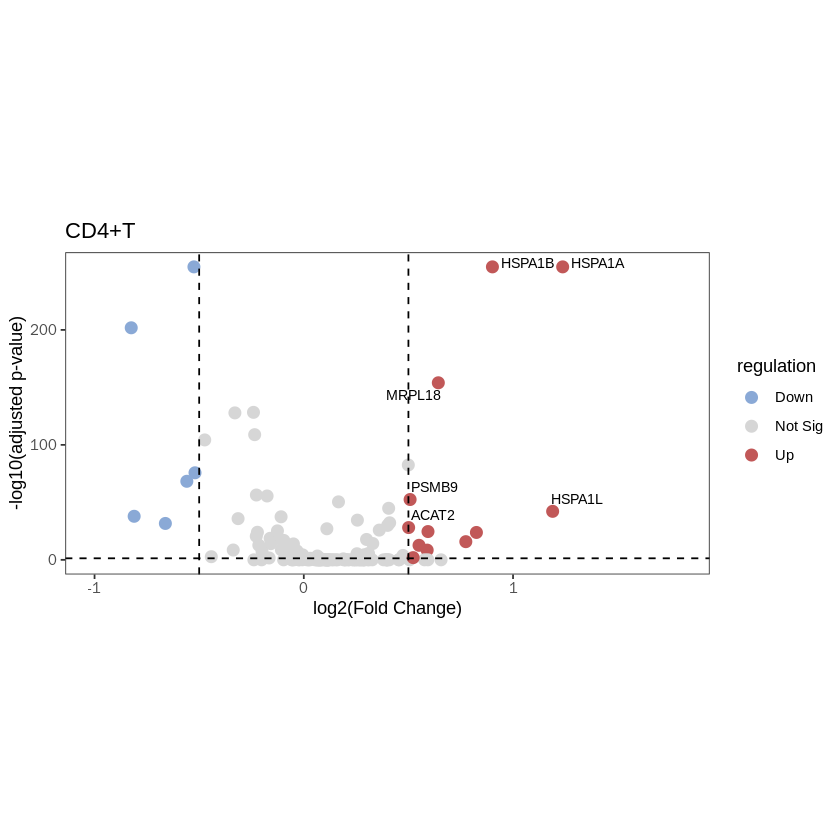

In [11]:
p3 <- ggplot(df, aes(x = avg_log2FC, y = negLogP, color = regulation)) +
  geom_point(alpha = 1, size = 3) +
  scale_color_manual(values = c("Down"="#8AA9D6", "Not Sig" = "#D6D6D6", "Up" = "#C15858")) +
  geom_vline(xintercept = c(-logFC_cutoff, logFC_cutoff), 
             linetype = "dashed", color = "black") +
  geom_hline(yintercept = -log10(pval_cutoff), 
             linetype = "dashed", color = "black") +
  theme_bw() +
  labs(x = "log2(Fold Change)", y = "-log10(adjusted p-value)", 
       title = "CD4+T")+theme(aspect.ratio = 1,panel.grid = element_blank(),
  )+xlim(-1,1.8)+geom_text_repel(
    data = upGenes,
    aes(label = gene),
    size = 3,
    color = "black",
    max.overlaps = 21  
  )+theme(aspect.ratio = 0.5)
p3

In [12]:
ct = 'CD8T'
DEG <- read.csv(paste0(ct,'_DEG_LD.csv'),row.names = 1)
meta = read.csv(paste0(ct,'_eqtl_meta_results_GWASrisk.csv'))

re = intersect(meta$Gene,rownames(DEG))

logFC_cutoff <- 0.5
pval_cutoff <- 0.05
DEG$negLogP <- -log10(DEG$p_val_adj)

df = DEG[re,]
# 添加显著性分组
df$regulation <- "Not Sig"
df$regulation[df$avg_log2FC > logFC_cutoff & df$p_val_adj < pval_cutoff] <- "Up"
df$regulation[df$avg_log2FC < -logFC_cutoff & df$p_val_adj < pval_cutoff] <- "Down"

max_finite <- max(df$negLogP[is.finite(df$negLogP)], na.rm = TRUE)

df$negLogP[is.infinite(df$negLogP)] <- max_finite

upGenes <- df[df$regulation == 'Up',]
upGenes= upGenes[order(upGenes$p_val_adj),][1:6,]
upGenes$gene = rownames(upGenes)

dim(df[df$regulation == 'Up',])

[1] 8 7

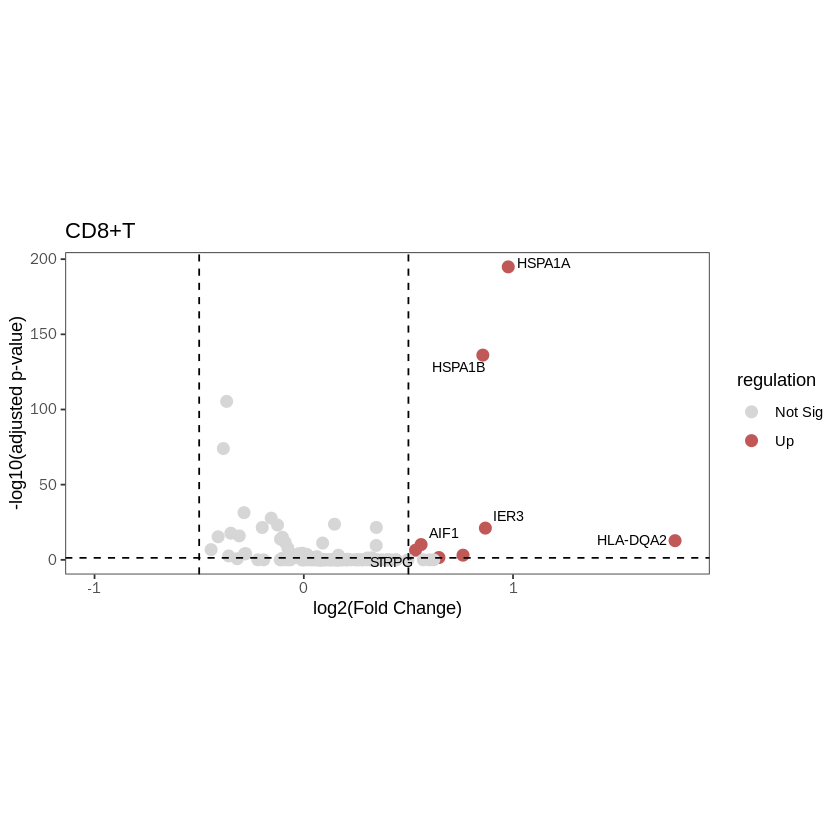

In [13]:
p4 <- ggplot(df, aes(x = avg_log2FC, y = negLogP, color = regulation)) +
  geom_point(alpha = 1, size = 3) +
  scale_color_manual(values = c("Down"="#8AA9D6", "Not Sig" = "#D6D6D6", "Up" = "#C15858")) +
  geom_vline(xintercept = c(-logFC_cutoff, logFC_cutoff), 
             linetype = "dashed", color = "black") +
  geom_hline(yintercept = -log10(pval_cutoff), 
             linetype = "dashed", color = "black") +
  theme_bw() +
  labs(x = "log2(Fold Change)", y = "-log10(adjusted p-value)", 
       title = "CD8+T")+theme(aspect.ratio = 1,panel.grid = element_blank(),
  )+xlim(-1,1.8)+geom_text_repel(
    data = upGenes,
    aes(label = gene),
    size = 3,
    color = "black",
    max.overlaps = 21  
  )+theme(aspect.ratio = 0.5)
p4